# Hands-on · Real tracks: loading experimental measurements and analyzing bacterial trajectories

The class notebooks NB1–NB3 use synthetic cells whose parameters we chose. This hands-on notebook opens real tracking experiments: three movies of swimming bacteria, tracked, and saved as MATLAB `.mat` files. The three files correspond to two types of bacteria in two different environments, and the goal is to reveal these species/environment differences through trajectory analysis we learned from the class.

What you do here:

* **Find** the data files and see what is in each of them.
* **Load** one file, look at its raw content, and **convert** it to the table format of the course (`track_id, frame, t, x_um, y_um`), so every tool of NB1 and NB2 applies.
* **Read the metadata off the data**: frame rate, duration, field of view, missing detections.
* **Plot trajectories** and visualize them before doing more complex analysis.

That is all. The last section lists what to try next. After this, you're ready to explore further in the class project :)

**Before you start.** The data are not in the repository (90 MB). Download the three files `dataset_1.mat`, `dataset_2.mat` and `dataset_3.mat` from the course Dropbox folder (`motility_module/data`; the link is given in class) and drag them into the folder **`data/experimental/`** of this repository. That folder exists already and holds a `README.txt` with the same instructions. Then run the notebook.

## 0 · Setup
Run this cell first. It loads the packages and the course package `motility` from the folder above `notebooks/`.

In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # the course package `motility` is in the folder above notebooks/
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from motility import io, plotting
from motility.plotting import COLORS

plotting.set_style()
rng = np.random.default_rng(5910)   # fixed seed: everyone gets the same figures

## 1 · The data folder

Each notebook runs from `notebooks/`, so the data folder is **`../data/experimental/`**: the folder `data/experimental/` of the repository, where you dropped the downloaded files. The cell below lists every `.mat` file it finds there, with what each contains: size, when MATLAB wrote it, its variables, and for the tracks the number of cells, the fields, the frame rate and the length of the movie (the last two measured from the time stamps). If the folder is empty it stops with instructions.

In [2]:
DATA_DIR = Path("../data/experimental")

available = io.mat_files_summary(DATA_DIR)
if available.empty:
    raise FileNotFoundError(
        f"No .mat file in {DATA_DIR.resolve()}.\n"
        "Download dataset_1.mat, dataset_2.mat and dataset_3.mat from the course Dropbox folder and drag them "
        "into that folder (see its README.txt), then run this cell again.")
available

,file,MB,created,variables,tracks_variable,n_tracks,fields,fps,movie_s
0,dataset_1.mat,43.8,Wed Nov 18 18:17:49 2026,tracks,tracks,4451,"x, y, time",20.0,600.0
1,dataset_2.mat,45.5,Wed Nov 18 18:41:46 2026,tracks,tracks,4560,"x, y, time",20.0,600.0
2,dataset_3.mat,3.0,Wed Nov 18 20:51:15 2026,tracks,tracks,2173,"x, y, time",30.3,300.0


Three experiments, three files with the same layout: one variable, `tracks`, with the fields `x`, `y` and `time`. They differ in the number of cells, the frame rate, the length of the movie, and (as you will see) the size of the field of view and how the cells move. Which organisms and conditions they are, you learn in class.

**Choose the dataset to analyze** in the next cell. Everything below runs on that file; come back here, change the name and run all again to look at another one.

In [3]:
DATASET = "dataset_1"                       # <- "dataset_1", "dataset_2" or "dataset_3"

DATA_FILE = DATA_DIR / f"{DATASET}.mat"
if not DATA_FILE.exists():
    raise FileNotFoundError(f"{DATA_FILE.name} is not in {DATA_DIR.resolve()}; the folder has: {list(available['file'])}")
print(f"analyzing {DATA_FILE.name} ({DATA_FILE.stat().st_size / 1e6:.1f} MB)")

analyzing dataset_1.mat (43.8 MB)


## 2 · What is inside a `.mat` file?

A `.mat` file is a container of named MATLAB variables. Before converting anything, list them: their names, types and shapes, and for a *struct* its fields. `io.describe_mat` does this. (It reads classic files with `scipy.io`, and `-v7.3` files, which are HDF5 inside, with `h5py`; you do not need MATLAB.)

In [4]:
io.describe_mat(DATA_FILE)

dataset_1.mat  (43.8 MB)
MATLAB 5.0 MAT-file, Platform: MACA64, Created on: Wed Nov 18 18:17:49 2026



tracks: struct array, 4451 elements, fields: x, y, time
   .x of element 1: float64 array, shape (7575,)
   .y of element 1: float64 array, shape (7575,)
   .time of element 1: float64 array, shape (7575,)


One variable, `tracks`: a **struct array** with one element per cell, and three fields, `x`, `y` and `time`, each an array with one value per frame of that cell. Nothing in the file says what the units are. That information lives in the lab notebook of whoever made the file (here: µm and s); the last section says how to check it.

`io.read_mat` gives the raw content as Python objects (a struct array becomes a list of dicts). The first track:

In [5]:
raw = io.read_mat(DATA_FILE)["tracks"]
first = raw[0]
print(f"{len(raw)} tracks; the first has {len(first['x'])} frames")
for k in ("x", "y", "time"):
    print(f"{k:>5}: {np.array2string(first[k][:5], precision=2)} ...")

4451 tracks; the first has 7575 frames
    x: [743.72 742.63 741.51 740.67 739.01] ...
    y: [608.35 608.71 609.63 609.81 610.75] ...
 time: [218.08 218.13 218.18 218.23 218.28] ...


## 3 · Into the course table, and the metadata

`io.load_mat_tracks` turns the struct array into the table used everywhere in this course: one row per detection, with `track_id`, `frame`, `t`, `x_um`, `y_um`. Two details matter:

* **Frames.** The file stores times, not frame numbers. The frame rate comes from the time steps, and `frame = round(t / Δt)` numbers the frames of the whole movie, so two cells filmed at the same instant share a frame number.
* **Missing detections.** Where the tracker lost a cell for a frame or two, the file holds `NaN`. By default these rows are dropped (`missing="drop"`), which leaves gaps in `frame`; `missing="interpolate"` fills them by linear interpolation instead, which the smoothing filters of NB1 need.

In [6]:
df, meta = io.load_mat_tracks(DATA_FILE)
df.head()

,track_id,frame,t,x_um,y_um
0,0,4361,218.084888,743.718107,608.347392
1,0,4362,218.134896,742.630317,608.706794
2,0,4363,218.184904,741.506236,609.629851
3,0,4364,218.234912,740.667807,609.812794
4,0,4365,218.284920,739.005499,610.746832


A real file rarely comes with a metadata sheet, so `load_mat_tracks` measures what it can from the data itself:

| entry | meaning |
|---|---|
| `fps`, `dt_s` | frame rate and time step, from the time stamps |
| `t_start_s`, `t_end_s` | first and last time stamp: the length of the movie |
| `track_duration_*` | shortest, median and longest track (trackers usually discard tracks below some length) |
| `x_range_um`, `y_range_um` | the field of view |
| `n_missing_positions`, `longest_gap_frames` | `NaN` positions, and the longest run of them within one track |

In [7]:
pd.Series(meta, name="value").to_frame()

,value
file,dataset_1.mat
description,"tracks from dataset_1.mat: variable 'tracks', ..."
n_tracks,4451
n_detections,1972471
fps,19.997
dt_s,0.050008
t_start_s,0.0
t_end_s,599.995984
track_duration_min_s,10.0016
track_duration_median_s,16.402624


How long the tracks are, and when they start during the movie (does the sample change over time?):

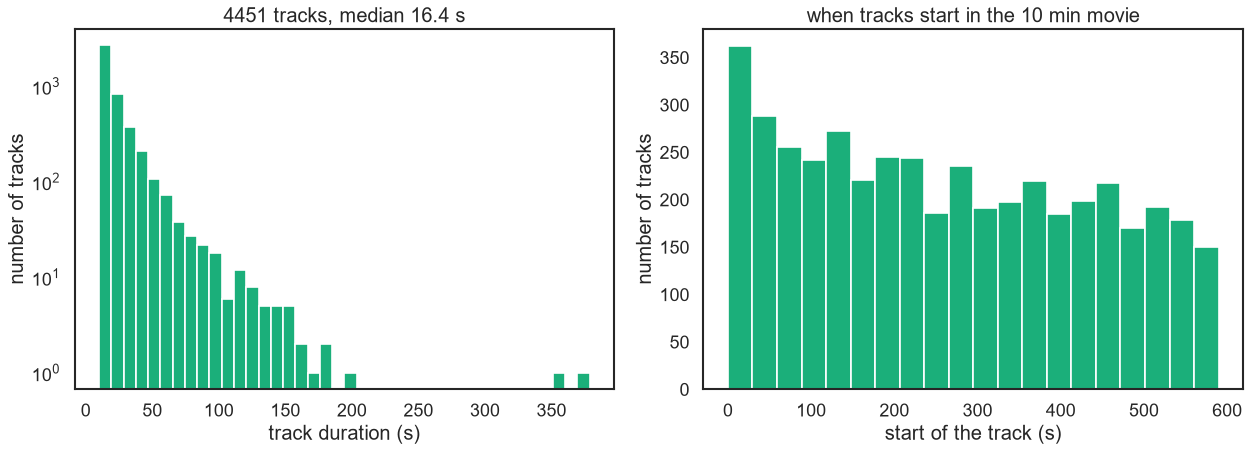

In [8]:
FPS = meta["fps"]
by_track = df.groupby("track_id")["t"]
durations, starts = by_track.max() - by_track.min(), by_track.min()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.hist(durations, bins=40, color=COLORS["run_tumble"])
ax1.set(xlabel="track duration (s)", ylabel="number of tracks", yscale="log",
        title=f"{len(durations)} tracks, median {durations.median():.1f} s")
ax2.hist(starts, bins=20, color=COLORS["run_tumble"])
ax2.set(xlabel="start of the track (s)", ylabel="number of tracks", title=f"when tracks start in the {meta['t_end_s'] / 60:.0f} min movie")
fig.tight_layout()
plt.show()

## 4 · Trajectories

Two views, each answering a different question.

**4.1 In the field of view.** Where were the cells, and do they cross the whole field or stay in one region? The longest tracks, in the coordinates of the camera:

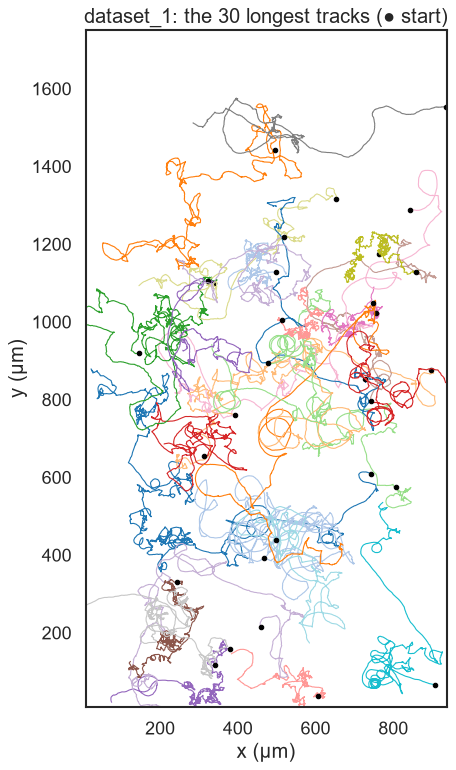

In [9]:
N_SHOW = 30
longest = durations.sort_values(ascending=False).index[:N_SHOW]

(x0, x1), (y0, y1) = meta["x_range_um"], meta["y_range_um"]
fig, ax = plt.subplots(figsize=(7, np.clip(7 * (y1 - y0) / (x1 - x0), 4, 11)))
for i, tid in enumerate(longest):
    one = df[df.track_id == tid]
    ax.plot(one["x_um"], one["y_um"], lw=1, color=plt.cm.tab20(i % 20))
    ax.plot(one["x_um"].iloc[0], one["y_um"].iloc[0], "o", ms=4, color="k")
ax.set(aspect="equal", xlim=(x0, x1), ylim=(y0, y1), xlabel="x (µm)", ylabel="y (µm)",
       title=f"{DATASET}: the {N_SHOW} longest tracks (● start)")
plt.show()

If many long tracks loop in circles, the cells were swimming within a few µm of the glass: near a wall the drag on the body and on the flagella differ, and the cell turns steadily. The longest tracks are long *because* those cells stay near the surface, in the focal plane: a selection effect to remember whenever you pick "the longest tracks".

**4.2 Moved to the origin.** To compare the *shapes* of tracks, as in NB1, move every track to start at the origin. A random sample, not the longest ones:

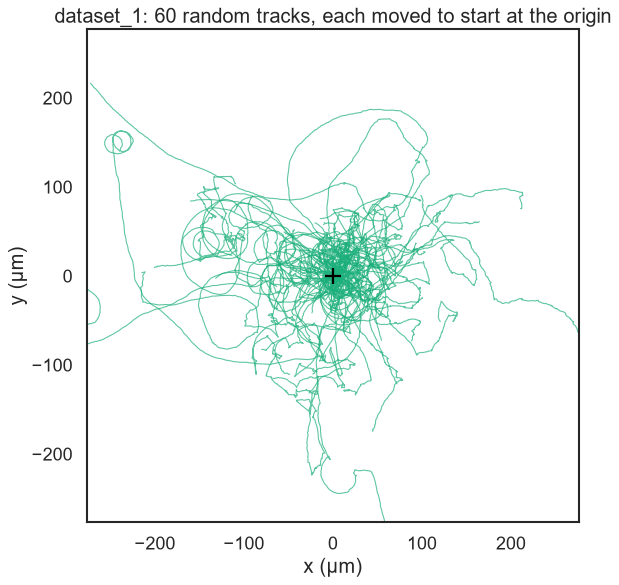

In [10]:
sample = rng.choice(df["track_id"].unique(), 60, replace=False)
centered = [df.loc[df.track_id == tid, ["x_um", "y_um"]].to_numpy() for tid in sample]
centered = [xy - xy[0] for xy in centered]
L = np.percentile(np.abs(np.concatenate(centered)), 99)         # axis limit: 99 % of the points fit

fig, ax = plt.subplots(figsize=(8, 8))
for xy in centered:
    ax.plot(xy[:, 0], xy[:, 1], lw=1, alpha=0.7, color=COLORS["run_tumble"])
ax.plot(0, 0, "+", color="k", ms=14, mew=2)
ax.set(xlim=(-L, L), ylim=(-L, L), aspect="equal", xlabel="x (µm)", ylabel="y (µm)",
       title=f"{DATASET}: 60 random tracks, each moved to start at the origin")
plt.show()

### 🔧 Try it 1 · Other cells, other datasets
> 1. Plot a single track on its own: `one = df[df.track_id == tid]` for one `tid` from `longest`, or a random one, `int(rng.choice(df["track_id"].unique()))`. Find a track with a clear run-tumble pattern, and one without. What does the second cell do instead?
> 2. Look at the longest track (`longest[0]`). Does it swim, circle, or sit stuck and wobble? What tells you?
> 3. Change `DATASET` in section 1 and run all again. Compare the three experiments: field of view, track lengths, shapes of the tracks, how far a cell gets in a few seconds.

## 5 · Where to go from here

This notebook only loads and looks. Each of these is a few lines with the tools you already have, and each answers a question you should ask of any new dataset:

* **One track, color-coded by time.** Plot a single track so that the color changes along it with time since its start: `ax.scatter(x, y, c=t - t[0], s=8, cmap="viridis")` plus `fig.colorbar(...)` is the quick way; `matplotlib.collections.LineCollection` draws it as a colored line. Runs appear as smooth stretches and tumbles as sharp kinks, and the color tells the direction of travel and where the cell was slow.
* **Occupancy in space.** `ax.hexbin(df["x_um"], df["y_um"], gridsize=60)`: is the whole field of view used, or do cells crowd somewhere (an edge, a bubble, a gradient)?
* **Do the units make sense?** Divide the distance between consecutive frames by Δt and plot the histogram of these raw speeds. *E. coli* swims at roughly 20 µm/s; a median far from what the organism is known to do means pixels, not µm, or a wrong frame rate. (Only count steps between consecutive frames of the same track, so that no step spans a dropped `NaN`.)
* **Color by speed instead of time**: where are the slow stretches, and are they short (tumbles) or long (stuck cells)?
* **Kinematics and states (NB1).** Load with `missing="interpolate"` so every track has consecutive frames, then `an.kinematics(df, FPS, window=...)` with a window of about 0.25 s (5 frames at 20 fps, 7 at 30 fps). Speed and angular velocity distributions, the $(v, \omega)$ plane, runs and tumbles.
* **MSD (NB2).** `an.msd` on the tracks: diffusive, ballistic or in between, and over which lag times?
* **Compare the three experiments** with the same figures. Which differences are biology (organism, condition) and which are the setup (magnification, frame rate, track length cutoff)?